# Лабораторная работа №4
## Нелинейная регрессия природного временного ряда

**Вариант:** станция NAIN, 2015 год.

В работе используется суточный ряд нейтронного монитора. Период гармонической составляющей является нелинейным параметром модели.


## Импорт и загрузка данных

Исходный ASCII-ответ NMDB кэшируется в `data`. При повторном запуске уже сохранённый файл используется без нового запроса.


## Исходный код программы

Следующая ячейка содержит полный код `main.py`. Остальные ячейки выполняют его этапы по отдельности и показывают промежуточные результаты.


In [42]:
from __future__ import annotations

from io import StringIO
from pathlib import Path
import json
import re

import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests


ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if (ROOT / "work_4").is_dir():
    ROOT = ROOT / "work_4"
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
STATION = "NAIN"
YEAR = 2015


def nmdb_url(start: pd.Timestamp, end: pd.Timestamp) -> str:
    params = {
        "formchk": 1,
        "stations[]": STATION,
        "tabchoice": "revori",
        "dtype": "corr_for_efficiency",
        "tresolution": 0,
        "yunits": 0,
        "date_choice": "bydate",
        "start_day": start.day,
        "start_month": start.month,
        "start_year": start.year,
        "start_hour": start.hour,
        "start_min": start.minute,
        "end_day": end.day,
        "end_month": end.month,
        "end_year": end.year,
        "end_hour": end.hour,
        "end_min": end.minute,
        "output": "ascii",
    }
    response = requests.get(
        "https://www.nmdb.eu/nest/draw_graph.php", params=params, timeout=180
    )
    response.raise_for_status()
    return response.text


def parse_nmdb(text: str) -> pd.Series:
    lines = [
        line.strip()
        for line in text.splitlines()
        if re.match(r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}.*;", line.strip())
    ]
    if not lines:
        raise ValueError("В ответе NMDB не найдены строки измерений")
    table = pd.read_csv(StringIO("\n".join(lines)), sep=";", header=None)
    index = pd.to_datetime(table[0], utc=True)
    values = pd.to_numeric(table[1], errors="coerce")
    return pd.Series(values.to_numpy(float), index=index).sort_index()


def load_year() -> pd.Series:
    cache = DATA_DIR / f"{STATION}_{YEAR}_30min.txt"
    if not cache.exists():
        start = pd.Timestamp(f"{YEAR}-01-01 00:00", tz="UTC")
        end = pd.Timestamp(f"{YEAR}-12-31 23:59", tz="UTC")
        cache.write_text(nmdb_url(start, end), encoding="utf-8")
    return parse_nmdb(cache.read_text(encoding="utf-8"))


def daily_series(series: pd.Series) -> pd.Series:
    daily = series.resample("1D").mean()
    full_index = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31", freq="D", tz="UTC")
    daily = daily.reindex(full_index)
    return daily.interpolate(limit_direction="both")


def design_matrix(t: np.ndarray, period: float) -> np.ndarray:
    angle = 2 * np.pi * t / period
    return np.column_stack([np.ones_like(t), t, np.sin(angle), np.cos(angle)])


def fit_period(t: np.ndarray, y: np.ndarray, period: float) -> tuple[np.ndarray, float, np.ndarray]:
    matrix = design_matrix(t, period)
    beta, *_ = np.linalg.lstsq(matrix, y, rcond=None)
    prediction = matrix @ beta
    return beta, float(np.mean((y - prediction) ** 2)), prediction


def golden_period(t: np.ndarray, y: np.ndarray, initial: float) -> tuple[float, np.ndarray, float, np.ndarray]:
    lower = max(2.0, initial / 2.0)
    upper = min(500.0, initial * 2.0)
    grid = np.geomspace(lower, upper, 160)
    losses = np.array([fit_period(t, y, p)[1] for p in grid])
    best_idx = int(losses.argmin())
    left = grid[max(0, best_idx - 1)]
    right = grid[min(len(grid) - 1, best_idx + 1)]
    if left == right:
        left, right = lower, upper
    phi = (1 + np.sqrt(5)) / 2
    c = right - (right - left) / phi
    d = left + (right - left) / phi
    fc = fit_period(t, y, c)[1]
    fd = fit_period(t, y, d)[1]
    for _ in range(80):
        if fc < fd:
            right, d, fd = d, c, fc
            c = right - (right - left) / phi
            fc = fit_period(t, y, c)[1]
        else:
            left, c, fc = c, d, fd
            d = left + (right - left) / phi
            fd = fit_period(t, y, d)[1]
    period = (left + right) / 2
    beta, loss, prediction = fit_period(t, y, period)
    return period, beta, loss, prediction


def metrics(y: np.ndarray, prediction: np.ndarray) -> dict[str, float]:
    residual = y - prediction
    ss_res = float(np.sum(residual**2))
    ss_tot = float(np.sum((y - y.mean()) ** 2))
    return {
        "RMSE": float(np.sqrt(np.mean(residual**2))),
        "MAE": float(np.mean(np.abs(residual))),
        "R2": 1 - ss_res / ss_tot,
        "residual_mean": float(residual.mean()),
        "residual_std": float(residual.std(ddof=0)),
    }


def main(show_plots: bool = False) -> dict:
    raw = load_year()
    daily = daily_series(raw)
    t = np.arange(len(daily), dtype=float)
    y = daily.to_numpy(float)
    initial_periods = [7.0, 27.0, 90.0, 180.0]
    rows = []
    fits = {}
    for initial in initial_periods:
        period, beta, loss, prediction = golden_period(t, y, initial)
        row = {"initial_period": initial, "period": period, **metrics(y, prediction)}
        rows.append(row)
        fits[initial] = (period, beta, prediction)
    comparison = pd.DataFrame(rows).sort_values(["RMSE", "initial_period"]).reset_index(drop=True)
    best_initial = float(comparison.iloc[0]["initial_period"])
    best_period, best_beta, best_prediction = fits[best_initial]
    residual = y - best_prediction
    result = {
        "station": STATION,
        "year": YEAR,
        "raw_observations": int(raw.notna().sum()),
        "days": int(len(daily)),
        "missing_after_interpolation": int(daily.isna().sum()),
        "best_initial_period": best_initial,
        "best_period": float(best_period),
        "coefficients": best_beta.tolist(),
        "metrics": metrics(y, best_prediction),
    }
    comparison.to_csv(DATA_DIR / "model_comparison.csv", index=False)
    daily.rename("daily_mean").to_csv(DATA_DIR / "daily_series.csv", header=True)
    (DATA_DIR / "summary.json").write_text(json.dumps(result, indent=2), encoding="utf-8")

    fig, ax = plt.subplots(figsize=(12, 4.8))
    ax.plot(daily.index, y, color="0.35", linewidth=0.8, label="Суточное среднее NAIN")
    ax.plot(daily.index, best_prediction, color="tab:red", linewidth=1.5, label=f"Модель, P = {best_period:.1f} суток")
    ax.set(title="Нелинейная регрессия суточного ряда NAIN за 2015 год", xlabel="Дата UTC", ylabel="RCORR_E")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "regression_fit.png", dpi=180)
    if show_plots:
        plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(12, 3.8))
    ax.plot(daily.index, residual, color="tab:blue", linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title="Остатки лучшей модели", xlabel="Дата UTC", ylabel="Наблюдение − модель")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "regression_residuals.png", dpi=180)
    if show_plots:
        plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
    axes[0].plot(raw.index, raw, color="tab:green", linewidth=0.45)
    axes[0].set(title="Исходные измерения NMDB", ylabel="RCORR_E")
    axes[1].plot(daily.index, daily, color="tab:purple", linewidth=0.8)
    axes[1].set(title="После агрегации до суток", ylabel="RCORR_E", xlabel="Дата UTC")
    for ax in axes:
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "raw_and_daily.png", dpi=180)
    if show_plots:
        plt.show()
    plt.close(fig)
    print(json.dumps(result, ensure_ascii=False, indent=2))
    print(comparison.to_string(index=False))
    return result

In [43]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

raw = load_year()
daily = daily_series(raw)
print('Получено измерений:', int(raw.notna().sum()))
print('Диапазон:', raw.index.min(), '—', raw.index.max())
print('Суточных наблюдений:', len(daily), 'пропусков после подготовки:', int(daily.isna().sum()))
display(daily.head())


Получено измерений: 17387
Диапазон: 2015-01-01 00:00:00+00:00 — 2015-12-31 23:30:00+00:00
Суточных наблюдений: 365 пропусков после подготовки: 0


2015-01-01 00:00:00+00:00    196.375583
2015-01-02 00:00:00+00:00    197.874542
2015-01-03 00:00:00+00:00    200.131021
2015-01-04 00:00:00+00:00    200.340521
2015-01-05 00:00:00+00:00    200.257104
Freq: D, dtype: float64

## Исходный и агрегированный ряд


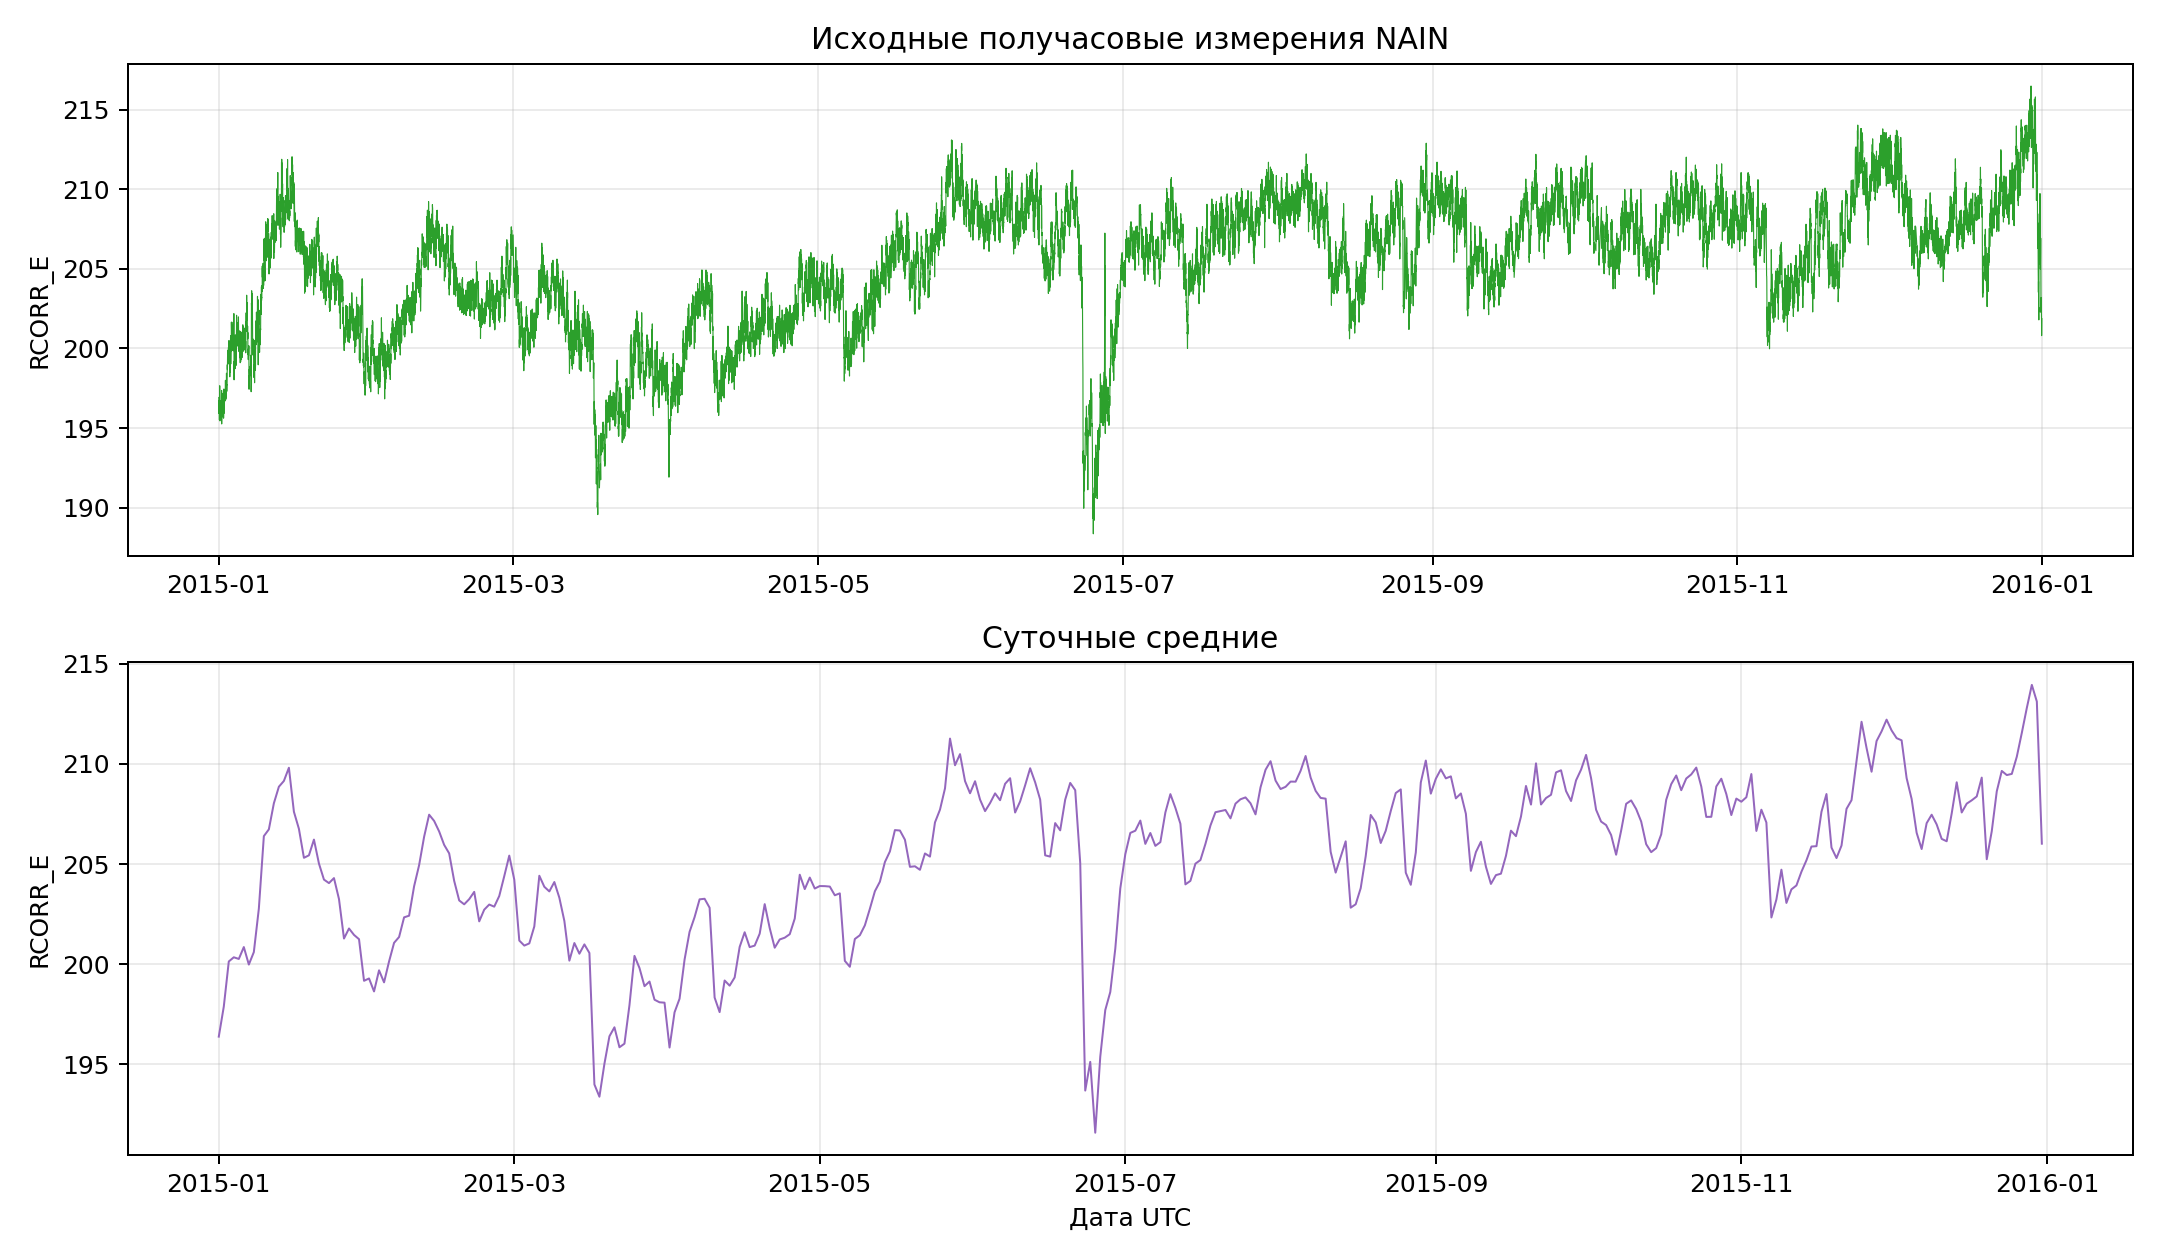

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
axes[0].plot(raw.index, raw, color='tab:green', linewidth=0.45)
axes[0].set(title='Исходные получасовые измерения NAIN', ylabel='RCORR_E')
axes[1].plot(daily.index, daily, color='tab:purple', linewidth=0.8)
axes[1].set(title='Суточные средние', ylabel='RCORR_E', xlabel='Дата UTC')
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / 'raw_and_daily_notebook.png', dpi=180)
display(Image(filename=str(FIG_DIR / 'raw_and_daily_notebook.png')))


## Оценка нелинейной модели

Для каждого пробного периода P линейные коэффициенты β₀…β₃ вычисляются заново методом наименьших квадратов. Сетка находит область минимума MSE, а золотое сечение уточняет период. Ниже показаны коэффициенты нескольких проб для P₀ = 90 суток.


In [45]:
import numpy as np

t = np.arange(len(daily), dtype=float)
y = daily.to_numpy(float)
initial_periods = [7.0, 27.0, 90.0, 180.0]
fits = {}
rows = []
for initial in initial_periods:
    period, beta, loss, prediction = golden_period(t, y, initial)
    fits[initial] = (period, beta, prediction)
    rows.append({'initial_period': initial, 'period': period, **metrics(y, prediction)})
comparison = pd.DataFrame(rows).sort_values(['RMSE', 'initial_period']).reset_index(drop=True)
display(comparison.round(6))

# Коэффициенты для пробных периодов
def coefficient_rows(t, y):
    grid = np.geomspace(45.0, 180.0, 160)
    i = min(range(len(grid)), key=lambda j: fit_period(t, y, grid[j])[1])
    left, right = grid[i - 1], grid[i + 1]
    phi = (1 + np.sqrt(5)) / 2
    periods = [90.0, grid[i], right - (right - left) / phi,
               left + (right - left) / phi, golden_period(t, y, 90.0)[0]]
    labels = ['Опорный P', 'Минимум сетки', 'Первая проба c', 'Первая проба d', 'После уточнения']
    return [(label, period, *beta, mse) for label, period in zip(labels, periods)
            for beta, mse, _ in [fit_period(t, y, period)]]


display(pd.DataFrame(coefficient_rows(t, y),
    columns=['Шаг', 'P, сут.', 'β₀', 'β₁', 'β₂', 'β₃', 'MSE']).round(5))


,initial_period,period,RMSE,MAE,R2,residual_mean,residual_std
0,180.0,116.504231,2.927119,2.275758,0.440361,0.0,2.927119
1,90.0,116.504230,2.927119,2.275758,0.440361,-0.0,2.927119
2,27.0,28.692933,2.950514,2.236631,0.431380,-0.0,2.950514
3,7.0,12.503112,3.083855,2.394823,0.378824,-0.0,3.083855


,Шаг,"P, сут.",β₀,β₁,β₂,β₃,MSE
0,Опорный P,90.00000,201.22471,0.02257,0.16775,-0.87003,9.43733
1,Минимум сетки,116.39799,200.85369,0.02440,1.64493,0.02269,8.56806
2,Первая проба c,116.16283,200.85894,0.02436,1.64418,0.00106,8.56839
3,Первая проба d,116.64199,200.84845,0.02443,1.64511,0.04512,8.56808
4,После уточнения,116.50423,200.85138,0.02441,1.64509,0.03246,8.56803


## Лучшая аппроксимация и остатки


Начальный период: 180.0
Оценённый период: 116.504231 суток
Метрики: {'RMSE': 2.927119, 'MAE': 2.275758, 'R2': 0.440361, 'residual_mean': 0.0, 'residual_std': 2.927119}


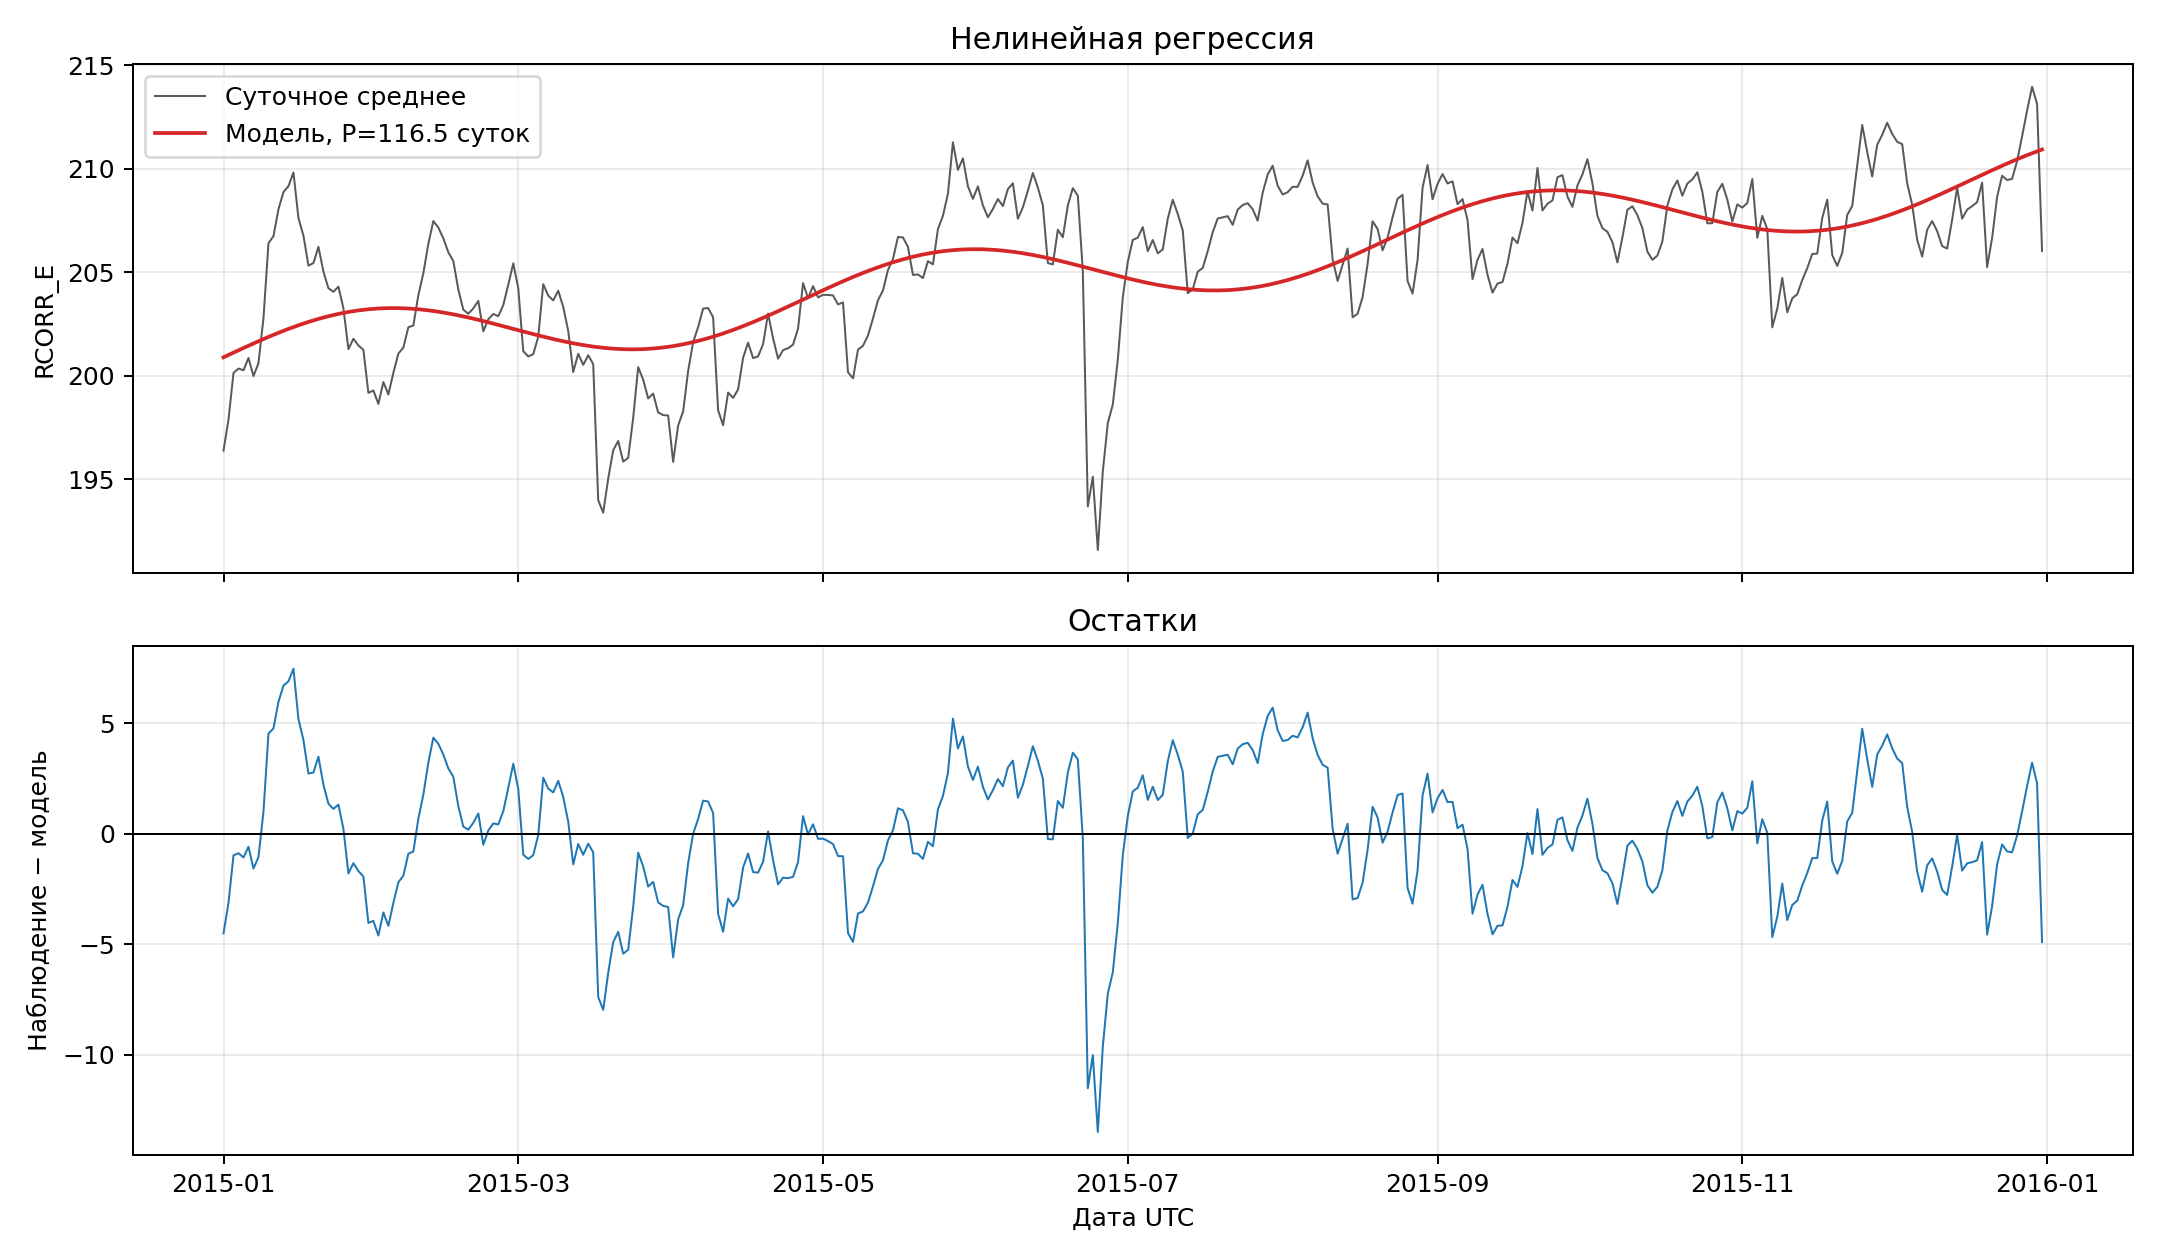

In [46]:
best_initial = float(comparison.iloc[0]['initial_period'])
best_period, best_beta, best_prediction = fits[best_initial]
best_metrics = metrics(y, best_prediction)
print('Начальный период:', best_initial)
print('Оценённый период:', round(best_period, 6), 'суток')
print('Метрики:', {k: round(v, 6) for k, v in best_metrics.items()})

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(daily.index, y, color='0.35', linewidth=0.8, label='Суточное среднее')
axes[0].plot(daily.index, best_prediction, color='tab:red', linewidth=1.5, label=f'Модель, P={best_period:.1f} суток')
axes[0].set(title='Нелинейная регрессия', ylabel='RCORR_E')
axes[0].legend()
residual = y - best_prediction
axes[1].plot(daily.index, residual, color='tab:blue', linewidth=0.8)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(title='Остатки', ylabel='Наблюдение − модель', xlabel='Дата UTC')
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / 'regression_fit_and_residuals_notebook.png', dpi=180)
display(Image(filename=str(FIG_DIR / 'regression_fit_and_residuals_notebook.png')))


## Вывод

Численные результаты и рисунки сохраняются скриптом `main.py` в каталогах `data` и `figures`. Отчёт содержит те же графики и таблицу сравнения запусков.
